# B1 · Shared data and correctness check

**Role:** produce the data every method is evaluated on, and label each answer as correct or wrong.

**Pipeline:** TriviaQA (50 questions, seed 42) → Qwen2.5-0.5B-Instruct → 1 greedy answer + 10 samples (with log likelihoods) → alias-matching label → `data/qwen0.5b/triviaqa_50.jsonl`

Code: `common/data.py`, `common/correctness.py`, `scripts/generate.py`, `scripts/label.py`, `scripts/manual_check.py`, tests in `tests/`.

## 1. Setup

In [ ]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Make `common` importable when the notebook runs from notebooks/
ROOT = Path.cwd() if (Path.cwd() / 'common').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from common.correctness import matching_alias
from common.data import DATA_DIR, load_data

pd.set_option('display.max_colwidth', 90)
rows = load_data('qwen0.5b', 50)
df = pd.DataFrame(rows)
print(f'{len(df)} questions, model: {df.model[0]}')
print('fields:', list(df.columns))

50 questions, model: Qwen/Qwen2.5-0.5B-Instruct
fields: ['id', 'question', 'aliases', 'greedy_answer', 'greedy_ll_sum', 'greedy_ll_mean', 'samples', 'samples_ll_mean', 'model', 'correct_alias', 'correct', 'samples_correct']


### Generation settings

| Setting | Value |
|---|---|
| Model | `Qwen/Qwen2.5-0.5B-Instruct` |
| Prompt | *Answer the following question with as few words as possible.* + question |
| Greedy answer | `do_sample=False`, max 32 new tokens |
| Samples | 10 per question, temperature 0.7, max 32 new tokens |
| Stopping | at the first newline; only tokens before the stop are scored |
| Seed | 42 (questions), 42 + id (samples) |

**Why stop at the newline?** The model often answered and then kept talking on the next line (e.g. `1822\nJean-Francois Champollion published ...`). Stopping keeps only the answer, and probly then computes the log likelihood over exactly the stored answer.

## 2. Accuracy

In [ ]:
n = len(df)
greedy_acc = df.correct.mean()
sample_acc = df.samples_correct.explode().astype(bool).mean()
n_words = df.greedy_answer.str.split().str.len()

summary = pd.Series({
    'questions': n,
    'greedy accuracy': f'{df.correct.sum()}/{n} = {greedy_acc:.0%}',
    'sample accuracy (500 samples)': f'{sample_acc:.0%}',
    'empty greedy answers': int((df.greedy_answer == '').sum()),
    'median answer length (words)': float(n_words.median()),
    'answers longer than 5 words': f'{(n_words > 5).sum()}/{n}',
})
summary.to_frame('value')

,value
questions,50
greedy accuracy,12/50 = 24%
sample accuracy (500 samples),21%
empty greedy answers,0
median answer length (words),7.5
answers longer than 5 words,28/50


**Accuracy is below the 30–70 % range we aimed for.** With only about 12 correct answers, every comparison between methods on these 50 questions will be noisy.

Many answers are full sentences although the prompt asks for as few words as possible; alias matching still works on them because it looks for the alias inside the answer.

## 3. Manual check of the automatic label

In [ ]:
manual = json.loads((DATA_DIR / 'qwen0.5b' / 'manual_check_50.json').read_text())
check = pd.DataFrame(manual['items']).merge(df[['id', 'question', 'greedy_answer']], on='id')
print(f"Agreement: {manual['agreement']:.0%} on {manual['n_checked']} answers "
      '(5 labelled correct, 5 labelled wrong, picked at random)')
check[['id', 'question', 'greedy_answer', 'auto', 'manual']]

Agreement: 100% on 10 answers (5 labelled correct, 5 labelled wrong, picked at random)


,id,question,greedy_answer,auto,manual
0,4,"""What year did Jean-Francois Champollion publish the first correct translation of Egyp...",1822,True,True
1,23,"Which Frenchman, a football administrator and head of FIFA from 1921 to1954 is regarde...",Paul Pogba,False,False
2,26,John Hannah and Ken Stott have both appeared in the role of which fictional detective?,"John Hannah has appeared in ""The Hound of the Baskervilles"" and ""The Case of the Missi...",False,False
3,27,Who was elected US President in November 2012?,Barack Obama was elected US President in November 2012.,True,True
4,30,Australian Shane Warne is associated with which sport?,Australian Shane Warne is associated with cricket.,True,True
5,32,Which is the only mythical creature found in the Chinese zodiac?,The only mythical creature found in the Chinese zodiac is the dragon.,True,True
6,33,Who had an 80s No 1 hit with Hold On To The Nights?,The Beatles,False,False
7,39,"What is the name of the life-size plastic dummies in the television series Doctor Who,...",Doctor Who Life-Size Dummies,False,False
8,48,"In which year was Sputnik, the first man-made satellite, launched?",1957,True,True
9,49,"Which war veterna, who died in 2009 had the nickname 'The Last Fighting Tommy'?",John Wayne Gacy,False,False


The automatic check agreed with the human label on all 10 answers. Ten answers is a small sample, so this shows the check is reasonable, not that it is perfect.

## 4. Example answers

In [ ]:
def show(qid):
    r = df.loc[df.id == qid].iloc[0]
    print(f'[{qid}] {r.question}')
    print(f'  greedy : {r.greedy_answer!r}  (correct={r.correct}, ll_mean={r.greedy_ll_mean:.2f})')
    print(f'  answer : {r.aliases[0]}   matched alias: {matching_alias(r.greedy_answer, r.aliases)}')
    print(f'  samples: {r.samples}')
    print()

show(4)   # confident and correct
show(19)  # confident and wrong: a hallucination
show(0)   # wrong country

[4] "What year did Jean-Francois Champollion publish the first correct translation of Egyptian hieroglyphs from the Rosetta Stone, the Roman Catholic Church take Galileo Galilei's ""Dialogue"" off their list of banned books, and Britain repeal the death penalty for over 100 crimes?"
  greedy : '1822'  (correct=True, ll_mean=-0.35)
  answer : 1822   matched alias: 1822
  samples: ['1822', '1822', '1822', '1822', '1822', '1928', '1822', '1822', '1822', '1822']

[19] Who had a top album in 1985 with Like A Virgin
  greedy : 'The artist who had a top album in 1985 with "Like A Virgin" was Michael Jackson.'  (correct=False, ll_mean=-0.40)
  answer : Madonna   matched alias: None
  samples: ['David Bowie', 'Jay-Z', 'Taylor Swift', 'The Beatles', 'Taylor Swift', 'The singer who had a top album in 1985 with "Like A Virgin" was Madonna.', 'The person who had a top album in 1985 with "Like A Virgin" was Prince.', 'Taylor Swift', 'Taylor Swift', 'The singer who had a top album in 1985 with "Like 

## 5. First look: do the stored scores relate to correctness?

Only a sanity check that the data carries a signal; the actual comparison of methods (AUROC, AURC) is done by B2's `evaluate()`.

In [ ]:
df['samples_agreeing'] = [
    sum(s.lower() == r.greedy_answer.lower() for s in r.samples) for r in df.itertuples()
]
df.groupby('correct')[['greedy_ll_mean', 'samples_agreeing']].mean().round(2)

,greedy_ll_mean,samples_agreeing
correct,,
False,-0.72,2.03
True,-0.35,4.67


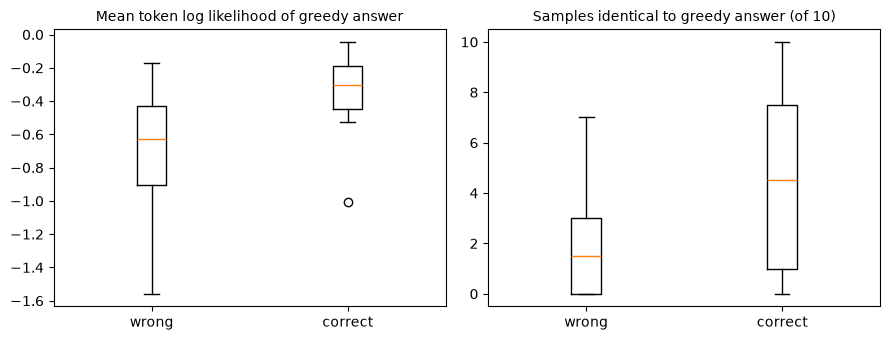

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, col, title in [
    (axes[0], 'greedy_ll_mean', 'Mean token log likelihood of greedy answer'),
    (axes[1], 'samples_agreeing', 'Samples identical to greedy answer (of 10)'),
]:
    data = [df.loc[~df.correct, col], df.loc[df.correct, col]]
    ax.boxplot(data, tick_labels=['wrong', 'correct'])
    ax.set_title(title, fontsize=10)
fig.tight_layout()
plt.show()

Correct answers have a higher likelihood and the samples agree with them more often, so the data carries an uncertainty signal for the methods to pick up.

## 6. Likelihood baseline

The simplest uncertainty score costs nothing extra: how unlikely the model found its own greedy answer (`scripts/baseline_likelihood.py`). `likelihood_mean` uses the mean token log likelihood, `likelihood_sum` the summed one. Below, every score file in `results/qwen0.5b/` is evaluated with B2's `evaluate()` and a bootstrap 95 % interval for the AUROC (0.5 = random, 1.0 = perfect).

In [ ]:
from common.evaluate import bootstrap_auroc, evaluate
from common.io import RESULTS_ROOT, load_scores

ids, correct = df.id.tolist(), df.correct.tolist()
table = []
for path in sorted((RESULTS_ROOT / 'qwen0.5b').glob('*.json')):
    rec = load_scores(path, expected_ids=ids)
    res = evaluate(rec['uncertainty'], correct)
    lo, hi = bootstrap_auroc(rec['uncertainty'], correct)
    table.append({
        'method': rec['method'],
        'AUROC': round(res['auroc'], 2),
        '95% CI': f'[{lo:.2f}, {hi:.2f}]',
        'CI above 0.5': lo > 0.5,
        'AURC (lower = better)': round(res['aurc'], 3),
    })
pd.DataFrame(table).sort_values('AUROC', ascending=False).reset_index(drop=True)

,method,AUROC,95% CI,CI above 0.5,AURC (lower = better)
0,likelihood_mean,0.81,"[0.66, 0.94]",True,0.605
1,likelihood_sum,0.66,"[0.45, 0.85]",False,0.664
2,p_true_zeroshot_norm,0.65,"[0.45, 0.83]",False,0.672


`likelihood_mean` is the only score so far whose interval stays above 0.5. The intervals still overlap, so with only 12 correct answers we cannot rank the methods; the baseline is the bar every method should clear.

## 7. Data quality notes

In [ ]:
n_alias = df.aliases.str.len()
print(f'aliases per question: median {n_alias.median():.0f}, max {n_alias.max()}')
print('broken characters in questions:', int(df.question.str.contains('Â').sum()))
print()
ford = df.loc[df.id == 1].iloc[0]
print('Some aliases are loose. Accepted answers for', repr(ford.question))
print([a for a in ford.aliases if not any(k in a.lower() for k in ('ford', 'king', 'president'))])

aliases per question: median 6, max 131
broken characters in questions: 1

Some aliases are loose. Accepted answers for 'Which US President was born Lesley Lynch King Jr?'
['Gerald fod', 'Nixon pardon']


## 8. What works / what does not

**Works**
- One shared, reproducible data file for all methods (fixed seeds, one command to regenerate, generation resumes after interruption)
- Stopping at the first newline gives clean answers with matching log likelihoods
- Alias matching agreed with the manual check on 10/10 answers; unit tests in `tests/`
- The free likelihood baseline (`likelihood_mean`) reaches AUROC 0.81 [0.66, 0.94]

**Does not work (yet)**
- Accuracy is only 24 %, so results on 50 questions are noisy
- The model often ignores *as few words as possible* and answers in full sentences
- TriviaQA aliases are noisy (e.g. *Nixon pardon* is accepted for Gerald Ford)
- Qwen's default `top_p=0.8` / `top_k=20` stayed active for sampling

## 9. Questions for the tutors
1. Accuracy is 24 %. Should we generate the main data with Qwen2.5-1.5B instead?
2. Is alias matching enough for correctness, or should we use NLI or an LLM judge?
3. Should sampling for semantic entropy use the model's default `top_p` / `top_k`, or plain temperature sampling?